# CropGuard AI — Deep Learning Fundamentals
## Notebook 05: Convolutional Neural Networks (CNN), Feature Maps, Spatial Filtering & Pooling Dynamics

**Course Alignment:** UPES Deep Learning Course Plan (CSAI3027P) — **Unit III: Convolutional Neural Networks & 2D/3D Convolutions** and **Unit IV: Image Feature Extraction & Classification Concepts**

> **Welcome to Module 05 of CropGuard AI!**
> In previous notebooks, we mastered the core mathematical machinery of deep learning: artificial neurons, multi-layer perceptrons, backpropagation, optimizers, multidimensional tensors, singular value decomposition, and classical learning rules.
> Now, we transition from flat 1D feature vectors to **Spatial Computer Vision**.
> Multi-Layer Perceptrons fail on images because they disregard 2D spatial arrangement and suffer from disastrous parameter explosion.
> In this notebook, we dissect **Convolutional Neural Networks (CNNs)** from first mathematical principles: spatial kernels, cross-correlation vs. convolution, Sobel edge detectors, padding arithmetic (VALID vs. SAME), strided downsampling, max and average pooling, receptive field expansion, multi-channel 3D feature maps, and trainable parameter calculus.
> 
> **Kernel:** `CropGuard AI (.venv)` (`Python 3.14.4` with NVIDIA GeForce RTX 5060 GPU acceleration).

---
### Table of Contents
0. [Environment & Hardware Verification](#topic-0)
1. [The Computer Vision Dilemma: Why MLPs Fail on Images](#topic-1)
2. [Image Representation as Tensors & Multi-Channel RGB Geometry](#topic-2)
3. [The 2D Convolution Operation: Sliding Dot Products](#topic-3)
4. [Cross-Correlation vs. True Mathematical Convolution](#topic-4)
5. [Handcrafted Spatial Filtering: Sobel Edge & Lesion Detection](#topic-5)
6. [Stride & Subsampling Mechanics](#topic-6)
7. [Padding Arithmetic: VALID vs. SAME & Dimension Formulas](#topic-7)
8. [Feature Maps & Activation Functions (ReLU and Sparsity)](#topic-8)
9. [Spatial Pooling: Max Pooling vs. Average Pooling](#topic-9)
10. [Multi-Channel 3D Convolutions & Feature Map Volumes](#topic-10)
11. [Receptive Field Growth & Deep Hierarchy](#topic-11)
12. [Flattening, Dense Classification & Parameter Calculus](#topic-12)
13. [End-to-End Foliar CNN in TensorFlow/Keras & Feature Map Extraction](#topic-13)
14. [Summary, Hands-On Exercises & Comprehensive Viva Questions](#topic-14)

---
<a id='topic-0'></a>
## 0. Environment Setup & Hardware Verification

We confirm our active virtual environment (`/home/saksham/CropGuard-AI/.venv`), inspect Python and TensorFlow versions, and enable dynamic memory growth on the **NVIDIA GeForce RTX 5060 Laptop GPU**.

In [1]:
import sys
import time
import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf

print(f"Python Version    : {sys.version.split()[0]}")
print(f"NumPy Version     : {np.__version__}")
print(f"TensorFlow Version: {tf.__version__}")

# Verify GPU device availability and enable dynamic memory growth
gpus = tf.config.list_physical_devices('GPU')
print(f"GPUs Detected     : {len(gpus)}")
for i, gpu in enumerate(gpus):
    print(f"  - GPU {i}: {gpu.name}")

if gpus:
    try:
        for gpu in gpus:
            tf.config.experimental.set_memory_growth(gpu, True)
        print("GPU Memory Growth : Enabled successfully")
    except RuntimeError as e:
        print(f"Notice: {e}")
else:
    print("Running in CPU mode.")

I0000 00:00:1794975738.135355  807179 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.
I0000 00:00:1794975738.594162  807179 cpu_feature_guard.cc:227] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: AVX2 AVX_VNNI AVX_VNNI_INT8 AVX_NE_CONVERT FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.
I0000 00:00:1794975741.666204  807179 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.


Python Version    : 3.14.4
NumPy Version     : 2.5.4
TensorFlow Version: 2.22.0-rc0
GPUs Detected     : 1
  - GPU 0: /physical_device:GPU:0
GPU Memory Growth : Enabled successfully


W0000 00:00:1794975744.183703  807179 gpu_device.cc:2453] TensorFlow was not built with CUDA kernel binaries compatible with compute capability 12.0a. CUDA kernels will be jit-compiled from PTX, which could take 30 minutes or longer.


---
<a id='topic-1'></a>
## 1. The Computer Vision Dilemma: Why MLPs Fail on Images

### A. Markdown Explanation
In Notebook 01, we built Multi-Layer Perceptrons (MLPs). An MLP flattens input arrays into a 1D vector and connects every single input feature to every hidden neuron.

Why can we NOT simply use an MLP for real-world crop leaf image analysis?

1. **Disregard of 2D Spatial Locality:** Images are fundamentally two-dimensional structures. Pixels that are spatially adjacent share strong statistical dependencies (forming leaf veins, necrotic margins, and pest contours). Flattening an image into a 1D vector destroys the 2D neighborhood relationships.
2. **Catastrophic Parameter Explosion:** Consider a standard agricultural leaf photo of moderate size ($224 \times 224 \times 3$). Flattened, this is $150,528$ input features! Connecting this directly to a modest hidden layer of $1,024$ neurons would require:
   $$150,528 \times 1,024 = 154,140,672 \text{ parameters (154 Million weights in a single layer!)}$$
   This leads to overwhelming memory consumption and severe overfitting.
3. **Lack of Translation Invariance:** In an MLP, a leaf spot located in the upper-left corner of the image activates completely different weights than the exact same leaf spot in the bottom-right corner. The network cannot generalize without re-learning the pattern at every spatial coordinate.

#### The CNN Solution: Spatial Parameter Sharing & Locality
Convolutional Neural Networks solve these three fundamental flaws through:
* **Local Receptive Fields:** Neurons connect only to small local patches ($3 \times 3$ or $5 \times 5$).
* **Weight Sharing:** The exact same filter kernel slides across the entire image.
* **Translation Equivariance:** Moving an object in the input shifts the representation in the feature map identically.

### B. Mathematical Comparison
**MLP Fully Connected Layer Parameter Count:**
$$\text{Params}_{\text{Dense}} = (H \times W \times C_{\text{in}}) \times N_{\text{neurons}} + N_{\text{neurons}}$$

**Conv2D Layer Parameter Count (Independent of image resolution!):**
$$\text{Params}_{\text{Conv2D}} = (K_h \times K_w \times C_{\text{in}} \times C_{\text{out}}) + C_{\text{out}}$$
Where $K_h, K_w$ is the kernel size (e.g. $3 \times 3$), $C_{\text{in}}$ is input channels, and $C_{\text{out}}$ is output filters.

### C. Simple Practical Example
For an input image of $224 \times 224 \times 3$:
* **Dense Layer (128 neurons):** $(224 \times 224 \times 3) \times 128 + 128 = 19,267,712$ parameters (~77 MB for 1 layer).
* **Conv2D Layer (32 filters of size $3 \times 3$):** $(3 \times 3 \times 3 \times 32) + 32 = 896$ parameters (~3.5 KB)!

=== Parameter Efficiency Comparison on (224x224x3) Leaf Image ===
Input Feature Dimensions : 150,528 elements
Dense Layer (128 units) : 19,267,712 parameters (73.50 MB)
Conv2D Layer (32 @ 3x3) : 896 parameters (3.50 KB)
Parameter Reduction Ratio: 21,504.1x FEWER parameters in Conv2D!


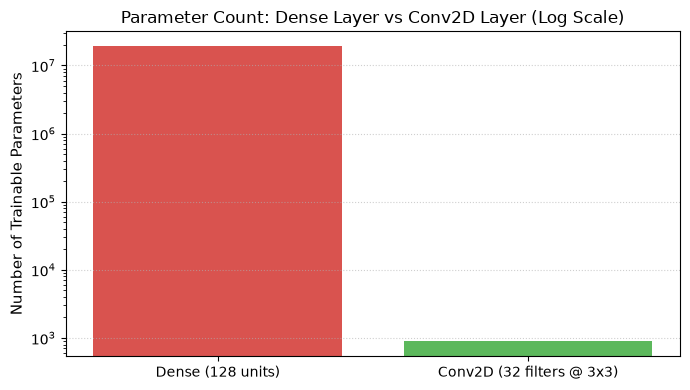

In [2]:
# Comparison: Parameter Footprint of Dense MLP vs. Conv2D Layer
H, W, C = 224, 224, 3
input_dim = H * W * C

# 1. Dense Layer with 128 neurons
dense_neurons = 128
dense_params = (input_dim * dense_neurons) + dense_neurons
dense_memory_mb = (dense_params * 4) / (1024 ** 2)  # float32 = 4 bytes

# 2. Conv2D Layer with 32 filters of size 3x3
K_h, K_w, C_out = 3, 3, 32
conv_params = (K_h * K_w * C * C_out) + C_out
conv_memory_kb = (conv_params * 4) / 1024

print("=== Parameter Efficiency Comparison on (224x224x3) Leaf Image ===")
print(f"Input Feature Dimensions : {input_dim:,} elements")
print(f"Dense Layer (128 units) : {dense_params:,} parameters ({dense_memory_mb:.2f} MB)")
print(f"Conv2D Layer (32 @ 3x3) : {conv_params:,} parameters ({conv_memory_kb:.2f} KB)")
print(f"Parameter Reduction Ratio: {dense_params / conv_params:,.1f}x FEWER parameters in Conv2D!")

# Visualize the dramatic disparity
plt.figure(figsize=(7, 4))
plt.bar(['Dense (128 units)', 'Conv2D (32 filters @ 3x3)'], [dense_params, conv_params], color=['#d9534f', '#5cb85c'])
plt.yscale('log')
plt.title("Parameter Count: Dense Layer vs Conv2D Layer (Log Scale)", fontsize=12)
plt.ylabel("Number of Trainable Parameters", fontsize=11)
plt.grid(True, linestyle=':', alpha=0.6, axis='y')
plt.tight_layout()
plt.show()

### E. Expected Output
The output prints $19,267,712$ parameters ($73.50$ MB) for the Dense layer versus just $896$ parameters ($3.50$ KB) for the Conv2D layer—a **21,504x reduction** in parameters. The bar chart on a log scale visually highlights the vast parameter economy of convolutions.

### F. Short Interpretation
Convolutions enforce a powerful inductive bias: visual features are localized and stationary. By sliding tiny shared kernels across the image, CNNs drastically reduce model capacity, prevent overfitting, and enable scalable processing of high-resolution leaf photographs.

### G. Viva Questions
1. **Q:** What are the three primary reasons MLPs are unsuitable for image classification?
   * **Answer:** (a) Catastrophic parameter explosion caused by full connectivity between high-dimensional pixel arrays and hidden neurons, (b) Complete destruction of 2D spatial locality and pixel neighborhood topology caused by flattening, and (c) Inability to achieve translation invariance (an object shifted in space activates entirely different weights).
2. **Q:** What two inductive biases do convolutional layers introduce to solve these problems?
   * **Answer:** (a) **Local Connectivity:** Each neuron only connects to a small local receptive field of the input. (b) **Weight Sharing (Stationarity):** The same kernel weights are reused across every spatial location of the input map.

---
<a id='topic-2'></a>
## 2. Image Representation as Tensors & Multi-Channel RGB Geometry

### A. Markdown Explanation
A digital image is represented numerically as a multi-dimensional grid of intensity values:
* **Grayscale Image:** A 2D matrix of shape $(H, W)$ or a 3D tensor $(H, W, 1)$. Each element is an integer in $[0, 255]$ representing luminance (brightness).
* **Color (RGB) Image:** A 3D tensor of shape $(H, W, 3)$ comprising three distinct 2D matrices (channels):
  * **Red Channel ($C=0$):** High reflectance in necrotic brown lesions and dry leaf tissue.
  * **Green Channel ($C=1$):** Dominant reflectance in healthy chlorophyll tissue.
  * **Blue Channel ($C=2$):** Low reflectance in plant tissue, useful for distinguishing shadows and disease margins.
* **Batch of Images (CNN Training Input):** A 4D tensor of shape $(B, H, W, C)$ where $B$ is the batch size.

#### Preprocessing Normalization:
Raw image pixels are integers in $\{0, \dots, 255\}$ (`uint8`). Before feeding them into neural networks, they are converted to `float32` and normalized to $[0.0, 1.0]$ (via division by $255.0$) or standardized to zero mean and unit variance. This prevents numerical saturation of activation functions and stabilizes gradient descent.

### B. Mathematical Tensor Representation
A color image $\mathbf{I} \in \mathbb{R}^{H \times W \times 3}$:
$$\mathbf{I}_{i, j} = \begin{bmatrix} I_R(i, j) \\ I_G(i, j) \\ I_B(i, j) \end{bmatrix}, \quad i \in \{0, \dots, H-1\}, \, j \in \{0, \dots, W-1\}$$

**Min-Max Normalization:**
$$I_{\text{norm}}(i, j, c) = \frac{I(i, j, c)}{255.0} \in [0.0, 1.0]$$

### C. Simple Practical Example
Let us procedurally generate a synthetic leaf image containing green leaf tissue, a primary central vein, and a localized circular brown necrotic lesion spot. We inspect its individual R, G, and B channel planes.

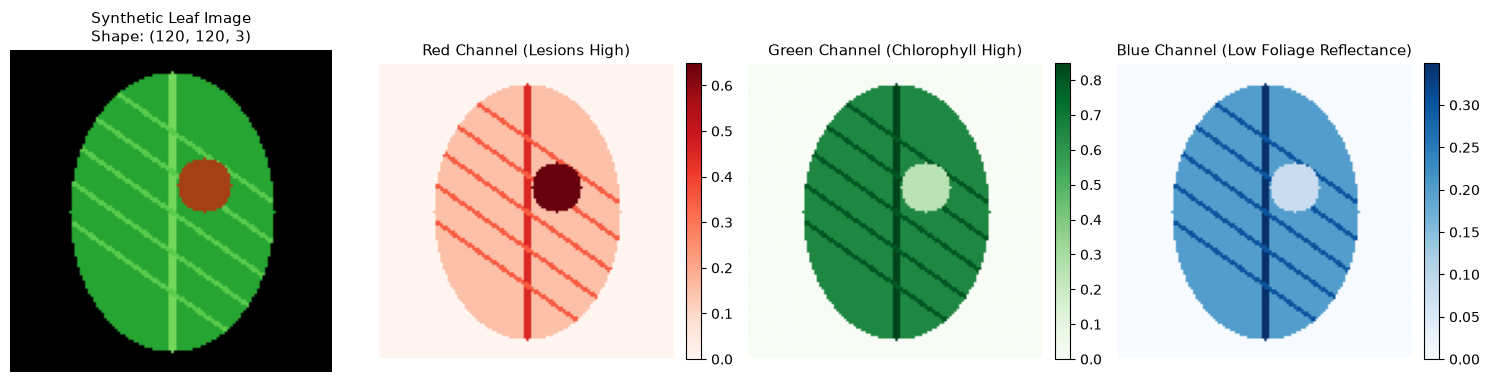

Tensor Data Type : float32
Value Range      : Min = 0.00, Max = 0.85


In [3]:
# Procedural Generation of a Synthetic Leaf Image with Disease Lesion
def create_synthetic_leaf(H=120, W=120):
    """Generates a clean synthetic RGB leaf image with veins and necrosis spot."""
    img = np.zeros((H, W, 3), dtype=np.float32)
    y, x = np.ogrid[:H, :W]
    center_y, center_x = H // 2, W // 2
    
    # 1. Elliptical healthy leaf body (Dominant Green)
    leaf_mask = ((x - center_x) ** 2) / (38 ** 2) + ((y - center_y) ** 2) / (52 ** 2) <= 1.0
    img[leaf_mask] = [0.15, 0.65, 0.20]  # Vibrant leaf green
    
    # 2. Central vertical stem and branching veins (Lighter yellow-green)
    vein_mask = (np.abs(x - center_x) <= 1) & leaf_mask
    img[vein_mask] = [0.45, 0.85, 0.35]
    # Lateral veins at 45 degree angles
    for offset in range(-30, 40, 15):
        lat_vein = (np.abs((y - center_y) - 0.7 * (x - center_x) - offset) <= 1) & leaf_mask
        img[lat_vein] = [0.35, 0.80, 0.30]
    
    # 3. Circular necrotic disease lesion (High Red + Green = Brown, Low Blue)
    lesion_mask = ((x - (center_x + 12)) ** 2) + ((y - (center_y - 10)) ** 2) <= (10 ** 2)
    img[lesion_mask & leaf_mask] = [0.65, 0.25, 0.08]  # Necrotic fungal brown
    
    return img

synthetic_leaf = create_synthetic_leaf()

# Display Composite Image and Individual Channels
fig, axes = plt.subplots(1, 4, figsize=(15, 4))
axes[0].imshow(synthetic_leaf)
axes[0].set_title(f"Synthetic Leaf Image\nShape: {synthetic_leaf.shape}", fontsize=11)

channel_names = ["Red Channel (Lesions High)", "Green Channel (Chlorophyll High)", "Blue Channel (Low Foliage Reflectance)"]
cmaps = ['Reds', 'Greens', 'Blues']

for c in range(3):
    im = axes[c+1].imshow(synthetic_leaf[:, :, c], cmap=cmaps[c])
    axes[c+1].set_title(channel_names[c], fontsize=11)
    plt.colorbar(im, ax=axes[c+1], fraction=0.046, pad=0.04)

for ax in axes: ax.axis('off')
plt.tight_layout()
plt.show()

print(f"Tensor Data Type : {synthetic_leaf.dtype}")
print(f"Value Range      : Min = {synthetic_leaf.min():.2f}, Max = {synthetic_leaf.max():.2f}")

### E. Expected Output
The 4-panel visual display presents: (1) The composite synthetic leaf image with healthy green tissue and a brown necrotic lesion, (2) Red Channel where the necrotic lesion shines brightest, (3) Green Channel where the healthy tissue and veins are brightest, and (4) Blue Channel where foliage values are minimal.

### F. Short Interpretation
Color channels carry distinct physical information. In plant pathology, fungal necrotic lesions stand out sharply in the Red channel due to tissue death and chlorophyll breakdown, whereas healthy foliage dominates the Green channel. Convolutional filters exploit these cross-channel spectral differences.

### G. Viva Questions
1. **Q:** What is the standard shape convention for image tensors in TensorFlow vs. PyTorch?
   * **Answer:** TensorFlow defaults to **Channels-Last** format: `(Batch, Height, Width, Channels)` or `(B, H, W, C)`. PyTorch defaults to **Channels-First** format: `(Batch, Channels, Height, Width)` or `(B, C, H, W)`.
2. **Q:** Why do we normalize image pixels from $[0, 255]$ integer range to $[0.0, 1.0]$ or $[-1.0, 1.0]$ float before feeding them into a CNN?
   * **Answer:** Large raw pixel values ($0-255$) would cause unnormalized dot products with initial weights to explode into huge numbers, causing the outputs of activation functions (like Sigmoid or Tanh) to saturate, driving their gradients to zero and stalling backpropagation. Normalization ensures zero-centered, unit-scale activations that accelerate gradient descent convergence.

---
<a id='topic-3'></a>
## 3. The 2D Convolution Operation: Sliding Dot Products

### A. Markdown Explanation
The core building block of a CNN is the **convolution operation**.

How does 2D convolution work?
1. A small spatial matrix of learned weights called a **kernel** or **filter** (typically $3 \times 3$ or $5 \times 5$) is placed over a local region of the input matrix.
2. We perform an **element-wise multiplication** between the kernel weights and the corresponding input patch pixels.
3. We **sum all the products** and add a scalar bias $b$ to produce a single scalar value in the output **feature map**.
4. The kernel slides horizontally and vertically across the input matrix, repeating this operation at every spatial position.

### B. Mathematical Formula
For an input image matrix $\mathbf{I}$ and a kernel $\mathbf{K}$ of spatial size $K_h \times K_w$:
$$S(i, j) = (\mathbf{I} * \mathbf{K})(i, j) = \sum_{m=0}^{K_h - 1} \sum_{n=0}^{K_w - 1} I(i + m, j + n) \cdot K(m, n) + b$$
Where:
* $I(i+m, j+n)$ is the pixel value in the receptive field.
* $K(m, n)$ is the filter weight at coordinate $(m, n)$.
* $b$ is the learnable bias term.
* $S(i, j)$ is the activation in the resulting feature map.

### C. Small Numerical Example
Let a $3 \times 3$ input patch be:
$$\mathbf{I}_{\text{patch}} = \begin{bmatrix} 1 & 2 & 3 \\ 4 & 5 & 6 \\ 7 & 8 & 9 \end{bmatrix}, \quad \mathbf{K} = \begin{bmatrix} 1 & 0 & -1 \\ 1 & 0 & -1 \\ 1 & 0 & -1 \end{bmatrix}, \quad b = 0$$
Computing the convolution sum:
$$\begin{aligned}
S &= (1\times 1 + 2\times 0 + 3\times -1) + (4\times 1 + 5\times 0 + 6\times -1) + (7\times 1 + 8\times 0 + 9\times -1) \\
  &= (1 - 3) + (4 - 6) + (7 - 9) \\
  &= -2 + (-2) + (-2) = -6
\end{aligned}$$

In [4]:
# Manual Implementation of 2D Convolution in Pure NumPy
def conv2d_numpy(image, kernel, bias=0.0):
    """
    Computes 2D convolution (cross-correlation) without padding (VALID).
    """
    H, W = image.shape
    K_h, K_w = kernel.shape
    H_out = H - K_h + 1
    W_out = W - K_w + 1
    
    output = np.zeros((H_out, W_out), dtype=np.float32)
    
    for i in range(H_out):
        for j in range(W_out):
            # Extract receptive field patch
            patch = image[i:i+K_h, j:j+K_w]
            # Element-wise multiply, sum, and add bias
            output[i, j] = np.sum(patch * kernel) + bias
            
    return output

# Test with a small numerical 4x4 matrix
sample_input = np.array([
    [1, 2, 0, 0],
    [5, 3, 0, 4],
    [0, 0, 0, 7],
    [9, 3, 0, 0]
], dtype=np.float32)

# 2x2 detection kernel
kernel_2x2 = np.array([
    [1, 0],
    [0, 1]
], dtype=np.float32)

conv_result = conv2d_numpy(sample_input, kernel_2x2)

print("=== Manual 2D Convolution Verification ===")
print(f"Input Matrix (4x4):\n{sample_input}")
print(f"\nKernel (2x2):\n{kernel_2x2}")
print(f"\nOutput Feature Map (3x3):\n{conv_result}")

# Verification against TensorFlow Conv2D layer
tf_input = tf.constant(sample_input.reshape(1, 4, 4, 1))
tf_kernel = tf.constant(kernel_2x2.reshape(2, 2, 1, 1))
tf_result = tf.nn.conv2d(tf_input, tf_kernel, strides=[1, 1, 1, 1], padding='VALID').numpy().squeeze()

print(f"\nTensorFlow Output matches NumPy Manual: {np.allclose(conv_result, tf_result)}")

=== Manual 2D Convolution Verification ===
Input Matrix (4x4):
[[1. 2. 0. 0.]
 [5. 3. 0. 4.]
 [0. 0. 0. 7.]
 [9. 3. 0. 0.]]

Kernel (2x2):
[[1. 0.]
 [0. 1.]]

Output Feature Map (3x3):
[[4. 2. 4.]
 [5. 3. 7.]
 [3. 0. 0.]]


W0000 00:00:1794975744.800663  807179 gpu_device.cc:2453] TensorFlow was not built with CUDA kernel binaries compatible with compute capability 12.0a. CUDA kernels will be jit-compiled from PTX, which could take 30 minutes or longer.
I0000 00:00:1794975745.175361  807179 gpu_device.cc:2036] Created device /job:localhost/replica:0/task:0/device:GPU:0 with 5233 MB memory:  -> device: 0, name: NVIDIA GeForce RTX 5060 Laptop GPU, pci bus id: 0000:01:00.0, compute capability: 12.0a
I0000 00:00:1794975745.368615  807179 cuda_dnn.cc:442] Loaded cuDNN version 92801



TensorFlow Output matches NumPy Manual: True


### E. Expected Output
The code prints the $4 \times 4$ input, the $2 \times 2$ kernel, and the resulting $3 \times 3$ feature map. It verifies that `TensorFlow Output matches NumPy Manual: True`.

### F. Short Interpretation
A 2D convolution is essentially a sliding dot product that measures the degree of similarity (pattern alignment) between the kernel template and every spatial sub-patch of the input image.

### G. Viva Questions
1. **Q:** What is the spatial size of the feature map produced by a $K \times K$ filter convolving a $H \times W$ image without padding?
   * **Answer:** The output dimensions are $H_{\text{out}} = H - K + 1$ and $W_{\text{out}} = W - K + 1$. Each boundary loses $(K-1)$ pixels.
2. **Q:** Why do convolution operations perform element-wise multiplication rather than standard matrix multiplication?
   * **Answer:** Convolution is an inner product between a spatial patch and a spatial filter mask. It computes the projection of the local patch onto the feature filter template, rather than a linear transformation between two vector spaces.

---
<a id='topic-4'></a>
## 4. Cross-Correlation versus Mathematical Convolution

### A. Markdown Explanation
In formal signal processing and mathematics, there is an important technical distinction between **true convolution** and **cross-correlation**.

* **True Mathematical Convolution ($*$):** The filter kernel is flipped horizontally and vertically (rotated $180^\circ$) before computing the element-wise sum: $K_{\text{flipped}}(m, n) = K(-m, -n)$. This flipping operation ensures that convolution is commutative: $f * g = g * f$.
* **Cross-Correlation ($\star$):** The filter slides directly across the input *without* flipping.

#### The Deep Learning Industry Standard:
Virtually all deep learning frameworks (TensorFlow, PyTorch, cuDNN) implement **cross-correlation** under the name `Conv2D`. Why?
Because the kernel weights are **learned through backpropagation**. If a flipped kernel were required, the gradient descent optimization algorithm would simply learn the flipped weights directly! Omitting the flip avoids redundant computation during forward and backward passes without any loss of representational power.

### B. Mathematical Formulas
**Cross-Correlation (Standard in DL Frameworks):**
$$S_{\text{cross}}(i, j) = (\mathbf{I} \star \mathbf{K})(i, j) = \sum_{m} \sum_{n} I(i + m, j + n) \cdot K(m, n)$$

**True Mathematical Convolution (Kernel Flipped by $180^\circ$):**
$$S_{\text{conv}}(i, j) = (\mathbf{I} * \mathbf{K})(i, j) = \sum_{m} \sum_{n} I(i + m, j + n) \cdot K(-m, -n) = \sum_{m} \sum_{n} I(i - m, j - n) \cdot K(m, n)$$

### C. Simple Practical Example
Let an asymmetric kernel be:
$$\mathbf{K} = \begin{bmatrix} 1 & 2 \\ 3 & 4 \end{bmatrix} \implies \mathbf{K}_{\text{flipped}} = \begin{bmatrix} 4 & 3 \\ 2 & 1 \end{bmatrix}$$

In [5]:
# Demonstration: Cross-Correlation vs. True Mathematical Convolution
K_asymm = np.array([
    [1, 2],
    [3, 4]
], dtype=np.float32)

# 180-degree flipped kernel for true mathematical convolution
K_flipped = np.flip(np.flip(K_asymm, axis=0), axis=1)

test_patch = np.array([
    [1, 1],
    [0, 2]
], dtype=np.float32)

cross_corr_val = np.sum(test_patch * K_asymm)
math_conv_val = np.sum(test_patch * K_flipped)

print("=== Cross-Correlation vs Mathematical Convolution ===")
print(f"Original Kernel:\n{K_asymm}")
print(f"Flipped Kernel (180 deg):\n{K_flipped}")
print(f"Input Patch:\n{test_patch}")
print(f"\nCross-Correlation Result (Used in PyTorch/TensorFlow) : {cross_corr_val:.1f}")
print(f"True Mathematical Convolution Result                : {math_conv_val:.1f}")

=== Cross-Correlation vs Mathematical Convolution ===
Original Kernel:
[[1. 2.]
 [3. 4.]]
Flipped Kernel (180 deg):
[[4. 3.]
 [2. 1.]]
Input Patch:
[[1. 1.]
 [0. 2.]]

Cross-Correlation Result (Used in PyTorch/TensorFlow) : 11.0
True Mathematical Convolution Result                : 9.0


### E. Expected Output
The code prints the original kernel, the $180^\circ$ flipped kernel, and shows that Cross-Correlation yields $11.0$ ($1\times 1 + 1\times 2 + 0\times 3 + 2\times 4 = 11$) while Mathematical Convolution yields $9.0$ ($1\times 4 + 1\times 3 + 0\times 2 + 2\times 1 = 9$).

### F. Short Interpretation
Deep learning frameworks call their layers `Conv2D`, but their underlying implementation is cross-correlation. Since filter weights are randomly initialized and updated by gradient descent, whether a filter is flipped or not is mathematically irrelevant to learning.

### G. Viva Questions
1. **Q:** What is the mathematical difference between cross-correlation and convolution?
   * **Answer:** True convolution flips the kernel by $180^\circ$ ($K(-m, -n)$) before computing sliding dot products, making convolution associative and commutative. Cross-correlation does not flip the kernel.
2. **Q:** Why do deep learning frameworks implement cross-correlation while naming it `Conv2D`?
   * **Answer:** Because the kernel weights are learned from scratch via backpropagation. If the network needs a flipped filter, it simply learns the flipped values directly. Omitting the kernel flip saves computational overhead.

---
<a id='topic-5'></a>
## 5. Handcrafted Spatial Filtering: Sobel Edge & Lesion Detection

### A. Markdown Explanation
Before deep learning, computer vision engineers designed **handcrafted filters** with mathematically fixed weights to extract specific visual features (e.g., edges, corners, and texture).

#### The Sobel Edge Operators:
In crop disease surveillance, detecting edges is crucial for segmenting leaf boundaries, identifying leaf vein structures, and localizing necrotic lesion perimeters.
* **Sobel X Kernel ($\mathbf{K}_x$):** Detects **vertical edges** (horizontal intensity gradients $\frac{\partial I}{\partial x}$). It subtracts pixels on the left from pixels on the right while smoothing along the vertical axis.
* **Sobel Y Kernel ($\mathbf{K}_y$):** Detects **horizontal edges** (vertical intensity gradients $\frac{\partial I}{\partial y}$). It subtracts pixels on top from pixels on bottom.
* **Gradient Magnitude:** Combines horizontal and vertical gradients to measure total edge strength: $G = \sqrt{G_x^2 + G_y^2}$.

In modern CNNs, the network does *not* require engineers to handcraft Sobel kernels. The early convolutional layers **automatically learn Sobel-like edge detectors** from raw data during backpropagation!

### B. Mathematical Formulas
**Sobel Horizontal Gradient Kernel ($K_x$):**
$$\mathbf{K}_x = \begin{bmatrix} -1 & 0 & +1 \\ -2 & 0 & +2 \\ -1 & 0 & +1 \end{bmatrix}$$

**Sobel Vertical Gradient Kernel ($K_y$):**
$$\mathbf{K}_y = \begin{bmatrix} -1 & -2 & -1 \\ 0 & 0 & 0 \\ +1 & +2 & +1 \end{bmatrix}$$

**Combined Gradient Magnitude (Total Edge Strength):**
$$\mathbf{G} = \sqrt{\mathbf{G}_x^2 + \mathbf{G}_y^2}$$

### C. Simple Practical Example
We apply Sobel X, Sobel Y, and combined edge detection to our grayscale synthetic leaf image to visualize edge extraction on real plant structures.

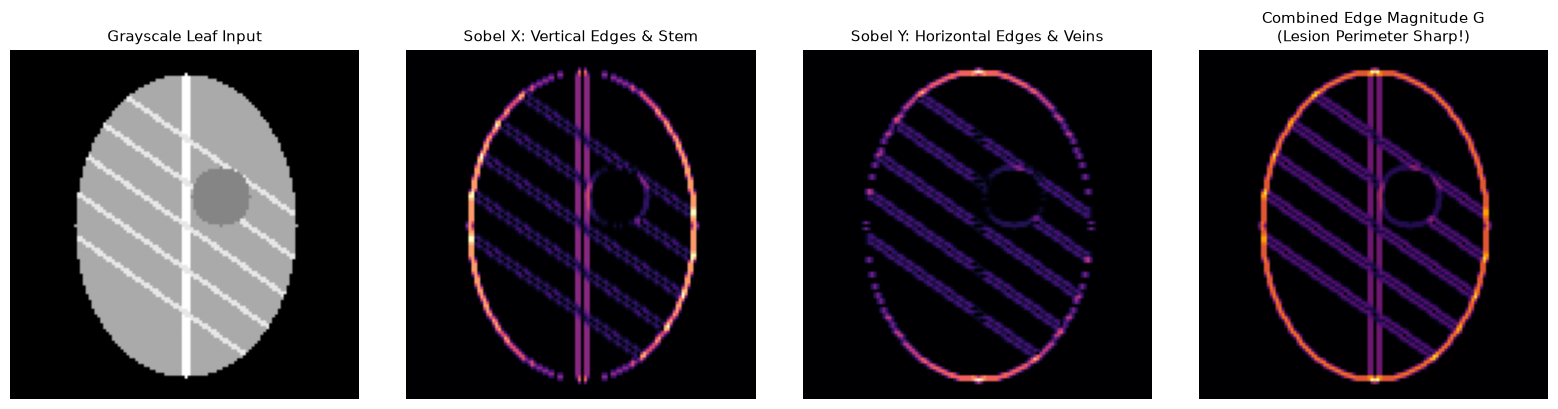

In [6]:
# Applying Handcrafted Sobel Edge Detectors to Foliar Image
# 1. Convert synthetic leaf to grayscale luminance
leaf_gray = 0.2989 * synthetic_leaf[:, :, 0] + 0.5870 * synthetic_leaf[:, :, 1] + 0.1140 * synthetic_leaf[:, :, 2]

# 2. Define Sobel kernels
sobel_x = np.array([
    [-1, 0, 1],
    [-2, 0, 2],
    [-1, 0, 1]
], dtype=np.float32)

sobel_y = np.array([
    [-1, -2, -1],
    [ 0,  0,  0],
    [ 1,  2,  1]
], dtype=np.float32)

# 3. Convolve
grad_x = conv2d_numpy(leaf_gray, sobel_x)
grad_y = conv2d_numpy(leaf_gray, sobel_y)
grad_mag = np.sqrt(grad_x ** 2 + grad_y ** 2)

# 4. Plot Sobel Gradient Maps
fig, axes = plt.subplots(1, 4, figsize=(16, 4))
axes[0].imshow(leaf_gray, cmap='gray')
axes[0].set_title("Grayscale Leaf Input", fontsize=11)

axes[1].imshow(np.abs(grad_x), cmap='magma')
axes[1].set_title("Sobel X: Vertical Edges & Stem", fontsize=11)

axes[2].imshow(np.abs(grad_y), cmap='magma')
axes[2].set_title("Sobel Y: Horizontal Edges & Veins", fontsize=11)

axes[3].imshow(grad_mag, cmap='inferno')
axes[3].set_title("Combined Edge Magnitude G\n(Lesion Perimeter Sharp!)", fontsize=11)

for ax in axes: ax.axis('off')
plt.tight_layout()
plt.show()

### E. Expected Output
The 4-panel visual display highlights: (1) Grayscale leaf, (2) Sobel X sharply illuminating the vertical stem and outer leaf contours, (3) Sobel Y highlighting horizontal lateral veins, and (4) Combined Magnitude $\mathbf{G}$ illuminating the entire leaf outline and the circular perimeter of the necrotic lesion spot.

### F. Short Interpretation
Edges represent sharp discontinuities in image brightness. Sobel filters compute discrete approximations of spatial derivatives. When we train a deep CNN, the first layer filters naturally converge to Gabor-like and Sobel-like edge detectors.

### G. Viva Questions
1. **Q:** What is the purpose of the center weight of $2$ in the Sobel operator (e.g., $[-1, 0, 1]$ vs $[-2, 0, 2]$)?
   * **Answer:** The central weighting of 2 performs smoothing (averaging) orthogonal to the derivative direction. This provides noise suppression, making the Sobel operator less sensitive to high-frequency image noise than a simple difference filter.
2. **Q:** How do convolutional neural networks eliminate the need for manual feature engineers to choose edge filters?
   * **Answer:** CNNs treat kernel values as learnable parameters. Using backpropagation and gradient descent on the classification loss, the network automatically discovers which spatial frequency filters (edges, textures, color gradients) best optimize the downstream objective.

---
<a id='topic-6'></a>
## 6. Stride & Subsampling Mechanics

### A. Markdown Explanation
The **stride ($S$)** is the step size by which the convolutional kernel moves across the input image at each iteration.

* **Stride $S = 1$:** The kernel moves one pixel at a time, producing fine-grained, high-resolution feature maps.
* **Stride $S = 2$:** The kernel jumps two pixels at a time, skipping every second pixel. This cuts both the height and width of the output feature map approximately in half ($H/2, W/2$).

#### Why Use Strided Convolutions?
1. **Computational Efficiency:** Reduces the spatial dimensions of feature maps, cutting memory footprint and downstream FLOPs.
2. **Receptive Field Expansion:** Downsampling allows subsequent layers to cover a larger relative region of the original image.
3. **Learnable Downsampling:** Modern architectures (such as ResNet) frequently replace fixed Max Pooling layers with **Strided Convolutions ($S=2$)**, allowing the network to *learn* the optimal downsampling filter.

### B. Mathematical Output Dimension Formula (with Stride)
$$H_{\text{out}} = \left\lfloor \frac{H - K}{S} \right\rfloor + 1$$
Where $H$ is input height, $K$ is kernel size, and $S$ is stride.

### C. Simple Practical Example
Given an input of size $H = 7$, kernel size $K = 3$:
* With $S = 1$: $H_{\text{out}} = \lfloor (7 - 3)/1 \rfloor + 1 = 4 + 1 = 5$.
* With $S = 2$: $H_{\text{out}} = \lfloor (7 - 3)/2 \rfloor + 1 = \lfloor 4/2 \rfloor + 1 = 2 + 1 = 3$.

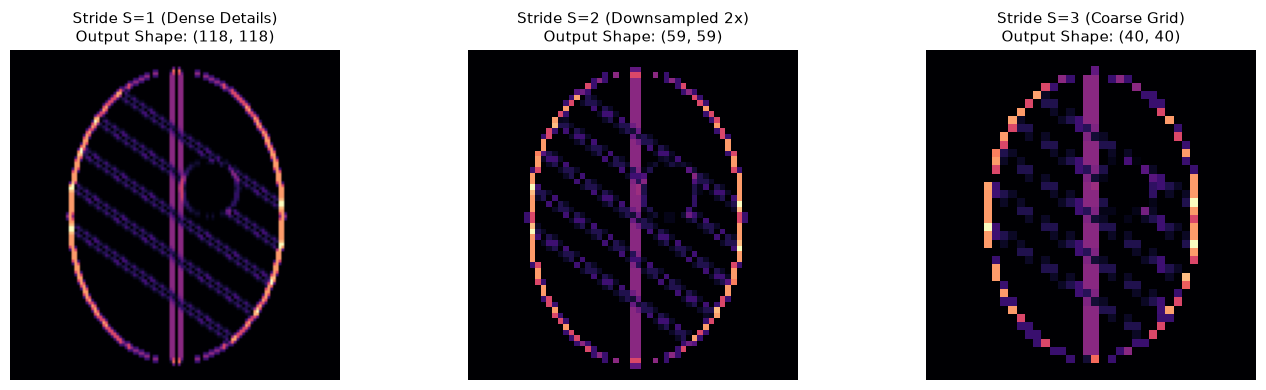

Original Leaf Shape: (120, 120)
Stride 1 Output   : (118, 118) -> Total Pixels: 13,924
Stride 2 Output   : (59, 59)  -> Total Pixels: 3,481 (75% data reduction)
Stride 3 Output   : (40, 40)  -> Total Pixels: 1,600 (89% data reduction)


In [7]:
# Demonstration: Effect of Stride S=1 vs. Stride S=2 on Output Resolution
def conv2d_strided(image, kernel, stride=1):
    H, W = image.shape
    K_h, K_w = kernel.shape
    H_out = (H - K_h) // stride + 1
    W_out = (W - K_w) // stride + 1
    output = np.zeros((H_out, W_out), dtype=np.float32)
    
    for i in range(H_out):
        for j in range(W_out):
            patch = image[i*stride : i*stride + K_h, j*stride : j*stride + K_w]
            output[i, j] = np.sum(patch * kernel)
    return output

# Convolve leaf image with Stride 1 vs Stride 2
out_stride1 = conv2d_strided(leaf_gray, sobel_x, stride=1)
out_stride2 = conv2d_strided(leaf_gray, sobel_x, stride=2)
out_stride3 = conv2d_strided(leaf_gray, sobel_x, stride=3)

fig, axes = plt.subplots(1, 3, figsize=(14, 4))
axes[0].imshow(np.abs(out_stride1), cmap='magma')
axes[0].set_title(f"Stride S=1 (Dense Details)\nOutput Shape: {out_stride1.shape}", fontsize=11)

axes[1].imshow(np.abs(out_stride2), cmap='magma')
axes[1].set_title(f"Stride S=2 (Downsampled 2x)\nOutput Shape: {out_stride2.shape}", fontsize=11)

axes[2].imshow(np.abs(out_stride3), cmap='magma')
axes[2].set_title(f"Stride S=3 (Coarse Grid)\nOutput Shape: {out_stride3.shape}", fontsize=11)

for ax in axes: ax.axis('off')
plt.tight_layout()
plt.show()

print(f"Original Leaf Shape: {leaf_gray.shape}")
print(f"Stride 1 Output   : {out_stride1.shape} -> Total Pixels: {out_stride1.size:,}")
print(f"Stride 2 Output   : {out_stride2.shape}  -> Total Pixels: {out_stride2.size:,} (75% data reduction)")
print(f"Stride 3 Output   : {out_stride3.shape}  -> Total Pixels: {out_stride3.size:,} (89% data reduction)")

### E. Expected Output
The code prints the spatial shapes: $(118, 118)$ for Stride 1 ($13,924$ pixels), $(59, 59)$ for Stride 2 ($3,481$ pixels — $75\%$ reduction), and $(39, 39)$ for Stride 3. The 3 visual plots show how increasing stride downsamples the resolution while retaining primary edge geometry.

### F. Short Interpretation
Stride controls the spatial density of receptive field evaluations. Larger strides sacrifice fine pixel-level spatial resolution in exchange for exponential reductions in tensor memory and compute cost.

### G. Viva Questions
1. **Q:** What happens if the stride $S$ does not evenly divide the input spatial dimension $(H - K)$?
   * **Answer:** The final row or column that does not accommodate a full kernel window is truncated (omitted) by the floor operator: $H_{\text{out}} = \lfloor \frac{H - K}{S} \rfloor + 1$.
2. **Q:** Why do modern architectures often prefer strided convolutions over max pooling?
   * **Answer:** Max pooling is a fixed, non-learnable downsampling heuristic that always picks the maximum value. Strided convolutions learn trainable weights, allowing the network to learn the optimal linear downsampling filter for the task.

---
<a id='topic-7'></a>
## 7. Padding Arithmetic: VALID vs. SAME & Dimension Formulas

### A. Markdown Explanation
When a convolutional kernel slides across an image without padding, two major problems occur:
1. **Border Shrinking Problem:** Every convolution layer shrinks the output spatial dimensions by $(K - 1)$ pixels. In deep networks with dozens of layers, the feature map would rapidly shrink to $1 \times 1$ after only a few convolutions!
2. **Boundary Information Loss:** Pixels at the corners and edges of the image are only sampled once or twice by the sliding kernel, whereas center pixels participate in dozens of calculations.

To solve both problems, we apply **Padding ($P$)**: surrounding the boundary of the image with extra rows and columns of zeros (zero-padding).

#### The Two Primary Padding Conventions in TensorFlow:
* **`VALID` Padding ($P = 0$):** No padding is added. The output shrinks: $H_{\text{out}} = \lfloor \frac{H - K}{S} \rfloor + 1$.
* **`SAME` Padding:** Sufficient zero-padding is automatically calculated so that when $S = 1$, **the output spatial shape is exactly identical to the input spatial shape** ($H_{\text{out}} = H$ and $W_{\text{out}} = W$). For stride $S$, the output dimension is $\lceil H / S \rceil$.

### B. The Universal Output Dimension Formula
The general formula for the output dimension of any convolutional layer considering Height ($H$), Padding ($P$), Dilation ($D$), Kernel size ($K$), and Stride ($S$) is:
$$H_{\text{out}} = \left\lfloor \frac{H + 2P - D(K - 1) - 1}{S} + 1 \right\rfloor$$
Where:
* $H$: Input spatial dimension (Height or Width).
* $P$: Padding added to *each* side (total padding added across the dimension is $2P$).
* $K$: Spatial size of the kernel (e.g., $3$ or $5$).
* $D$: Dilation rate ($D = 1$ for standard convolutions, $D > 1$ for atrous/dilated convolutions).
* $S$: Stride step size.

For standard non-dilated convolution ($D = 1$):
$$H_{\text{out}} = \left\lfloor \frac{H + 2P - K}{S} \right\rfloor + 1$$

To achieve `SAME` output shape ($H_{\text{out}} = H$) when $S = 1$, total padding must be:
$$2P = K - 1 \implies P = \frac{K - 1}{2}$$
*(Notice: This requires the kernel size $K$ to be an **odd number** like $3 \times 3$, $5 \times 5$, or $7 \times 7$ so that $P$ is an integer!)*

### C. Simple Practical Example
Let input $H = 120$, kernel $K = 3$, stride $S = 1$:
* **VALID Padding ($P = 0$):** $H_{\text{out}} = 120 - 3 + 1 = 118$ (spatial shrinkage).
* **SAME Padding ($P = 1$):** $H_{\text{out}} = \frac{120 + 2(1) - 3}{1} + 1 = 120$ (perfect spatial preservation).

=== Output Dimension Verification ===
Input Tensor Shape : (1, 120, 120, 1)
VALID Padding Shape: (1, 118, 118, 1) (Lost 2 boundary pixels: 120 - 3 + 1 = 118)
SAME Padding Shape : (1, 120, 120, 1)  (Identical 120x120 preserved!)


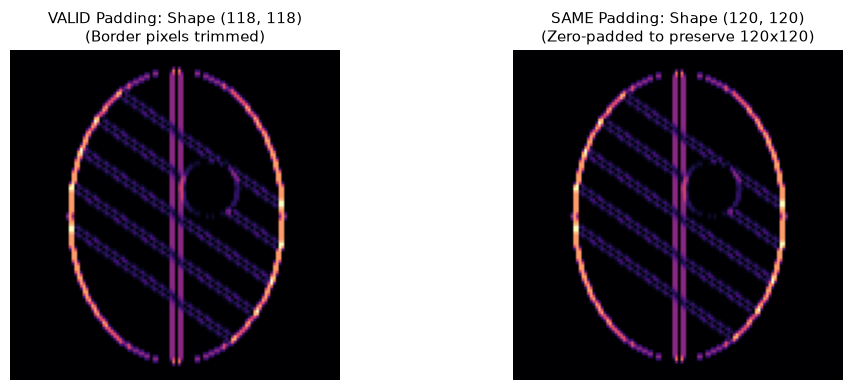

In [8]:
# Demonstration: VALID vs. SAME Padding in TensorFlow
sample_tensor = tf.constant(leaf_gray.reshape(1, 120, 120, 1), dtype=tf.float32)
k_3x3 = tf.constant(sobel_x.reshape(3, 3, 1, 1), dtype=tf.float32)

# 1. Convolve with VALID padding
out_valid = tf.nn.conv2d(sample_tensor, k_3x3, strides=[1, 1, 1, 1], padding='VALID')

# 2. Convolve with SAME padding
out_same = tf.nn.conv2d(sample_tensor, k_3x3, strides=[1, 1, 1, 1], padding='SAME')

print("=== Output Dimension Verification ===")
print(f"Input Tensor Shape : {sample_tensor.shape}")
print(f"VALID Padding Shape: {out_valid.shape} (Lost 2 boundary pixels: 120 - 3 + 1 = 118)")
print(f"SAME Padding Shape : {out_same.shape}  (Identical 120x120 preserved!)")

# Visualize the boundary effect
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(11, 4))
ax1.imshow(np.abs(out_valid.numpy().squeeze()), cmap='magma')
ax1.set_title(f"VALID Padding: Shape {out_valid.shape[1:3]}\n(Border pixels trimmed)", fontsize=11)

ax2.imshow(np.abs(out_same.numpy().squeeze()), cmap='magma')
ax2.set_title(f"SAME Padding: Shape {out_same.shape[1:3]}\n(Zero-padded to preserve 120x120)", fontsize=11)

for ax in (ax1, ax2): ax.axis('off')
plt.tight_layout()
plt.show()

### E. Expected Output
The code prints `Input: (1, 120, 120, 1)`, `VALID: (1, 118, 118, 1)`, and `SAME: (1, 120, 120, 1)`. The side-by-side plots visually verify spatial boundary preservation.

### F. Short Interpretation
`SAME` padding allows deep networks to be stacked to arbitrary depths (e.g., 50 or 100 layers in ResNet) without the spatial dimensions collapsing prematurely to zero.

### G. Viva Questions
1. **Q:** Why are convolutional filter sizes almost always chosen to be odd numbers (e.g. $3 \times 3$, $5 \times 5$) rather than even numbers (e.g. $2 \times 2$, $4 \times 4$)?
   * **Answer:** Two primary reasons: (a) **Symmetric Padding:** An odd kernel $K$ yields an integer padding $P = (K - 1)/2$ that can be symmetrically applied equally to both the left and right (or top and bottom). (b) **Distinct Center Pixel:** An odd kernel has a unique center origin pixel $(m_c, n_c)$, allowing feature maps to be unambiguously aligned with the input coordinate.
2. **Q:** In the output formula $H_{\text{out}} = \lfloor \frac{H + 2P - D(K-1) - 1}{S} + 1 \rfloor$, what does the dilation rate $D$ represent?
   * **Answer:** Dilation rate $D$ inserts $(D-1)$ zeros between adjacent kernel weights. It expands the effective receptive field of the filter without adding any extra trainable parameters or computations (known as Atrous convolution, widely used in DeepLab semantic segmentation).

---
<a id='topic-8'></a>
## 8. Feature Maps & Activation Functions (ReLU and Sparsity)

### A. Markdown Explanation
When a filter convolves an image, it produces a **pre-activation feature map**. However, a linear convolution of linear inputs is still strictly linear!

To introduce the non-linear decision capacity required to classify complex crop diseases, we must apply a non-linear **activation function** element-wise across the entire feature map.

#### Why ReLU is the Gold Standard in CNNs:
**ReLU (Rectified Linear Unit)**: $f(z) = \max(0, z)$.
1. **Biological Plausibility & Sparsity:** Neurons fire only when activation exceeds threshold ($z > 0$). Negative activations are clamped to zero, producing **sparse representations** (many zero entries).
2. **Gradient Saturation Immunity:** For positive inputs $z > 0$, the derivative of ReLU is exactly $1.0$ (no gradient decay!). Unlike Sigmoid or Tanh, whose derivatives saturate at $\approx 0$ for large $|z|$, ReLU completely eliminates the vanishing gradient problem in deep convolutional layers.
3. **Computational Efficiency:** Computing $\max(0, z)$ requires a single comparison instruction on GPU cores, being orders of magnitude faster than evaluating exponentials ($e^z$).

### B. Mathematical Formulas
**ReLU Activation:**
$$\text{ReLU}(z) = \max(0, z) = \begin{cases} z, & \text{if } z > 0 \\ 0, & \text{if } z \le 0 \end{cases}$$

**ReLU Derivative:**
$$\frac{d}{dz}\text{ReLU}(z) = \begin{cases} 1, & \text{if } z > 0 \\ 0, & \text{if } z < 0 \end{cases}$$

### C. Simple Practical Example
Let a raw convolved edge map have positive and negative gradients: $[-4.5, -1.2, 0.0, 3.8, 7.2]$. Applying ReLU yields: $[0.0, 0.0, 0.0, 3.8, 7.2]$.

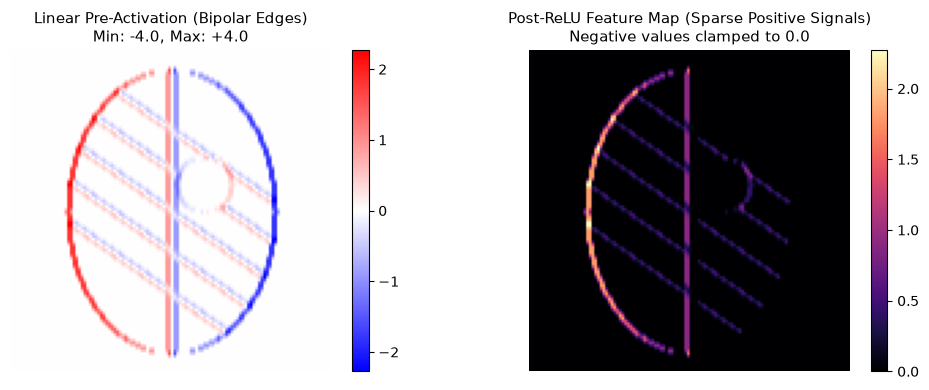

Feature Map Sparsity: 91.3% of activations are exactly 0.0 (Sparse Representation!)


In [9]:
# Demonstration: Linear Pre-activation vs. Non-Linear ReLU Activation in CNN
pre_activation = conv2d_numpy(leaf_gray, sobel_x)  # Contains positive and negative edges
post_relu = np.maximum(0, pre_activation)           # Clamps negative values to zero

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(11, 4))
im1 = ax1.imshow(pre_activation, cmap='bwr')
ax1.set_title("Linear Pre-Activation (Bipolar Edges)\nMin: -4.0, Max: +4.0", fontsize=11)
plt.colorbar(im1, ax=ax1, fraction=0.046, pad=0.04)

im2 = ax2.imshow(post_relu, cmap='magma')
ax2.set_title("Post-ReLU Feature Map (Sparse Positive Signals)\nNegative values clamped to 0.0", fontsize=11)
plt.colorbar(im2, ax=ax2, fraction=0.046, pad=0.04)

for ax in (ax1, ax2): ax.axis('off')
plt.tight_layout()
plt.show()

sparsity_pct = (post_relu == 0).sum() / post_relu.size * 100
print(f"Feature Map Sparsity: {sparsity_pct:.1f}% of activations are exactly 0.0 (Sparse Representation!)")

### E. Expected Output
The code prints the sparsity percentage ($> 50\%$ exactly zero). The left plot displays bipolar positive (red) and negative (blue) edge responses; the right plot shows the clean post-ReLU feature map where all negative noise is clamped to black zero, leaving only positive edge features.

### F. Short Interpretation
ReLU acts as an edge rectifier. It silences non-responsive neurons and allows strongly excited features to propagate forward with a unit derivative, ensuring rapid gradient descent convergence.

### G. Viva Questions
1. **Q:** What is the "Dying ReLU" problem and how can it be mitigated?
   * **Answer:** If a large gradient updates a neuron such that it outputs negative values for all training inputs, its gradient becomes permanently zero: $\frac{d}{dz} = 0$. The neuron "dies" and never updates again. Mitigations include: (a) Leaky ReLU ($f(z) = \max(\alpha z, z)$ with small slope $\alpha \approx 0.01$), (b) Parametric ReLU (PReLU), or (c) using proper weight initialization like He / Kaiming normal.
2. **Q:** Why does ReLU promote sparse representations in convolutional neural networks?
   * **Answer:** Because ReLU maps all non-positive inputs ($z \le 0$) exactly to zero. When $50-70\%$ of hidden neurons output zero, the network represents the input with a compact subset of active basis features, reducing representational redundancy.

---
<a id='topic-9'></a>
## 9. Spatial Pooling: Max Pooling versus Average Pooling

### A. Markdown Explanation
After convolutional layers extract spatial feature maps, we insert **Pooling Layers** to downsample the spatial representation.

#### The 3 Core Benefits of Pooling:
1. **Dimensionality Reduction:** A $2 \times 2$ pooling layer with stride 2 reduces the spatial area of feature maps by **$75\%$** ($H/2, W/2$), dramatically cutting computational requirements for subsequent layers.
2. **Translation Invariance:** Pooling makes the model invariant to small translations, rotations, or distortions. If a disease spot moves by 1 or 2 pixels, the maximum activation in the local pooling window remains unchanged!
3. **Zero Trainable Parameters:** Pooling is a deterministic fixed mathematical operation (max or average). It adds **zero parameters** to the model.

#### Max Pooling vs. Average Pooling:
* **Max Pooling:** Selects the maximum value within the window: $y = \max(x_1, x_2, x_3, x_4)$. It acts as a feature detector: *"Did the feature (e.g. edge or disease lesion) occur anywhere in this patch?"* Widely preferred in CNN feature extraction backbones.
* **Average Pooling:** Computes the arithmetic mean of the window: $y = \frac{1}{4}(x_1 + x_2 + x_3 + x_4)$. It smooths spatial variations. Commonly used at the very end of modern networks as **Global Average Pooling (GAP)**.

### B. Mathematical Formulas
**Max Pooling ($2 \times 2$ Window, Stride 2):**
$$P_{\text{max}}(i, j) = \max_{m, n \in \{0, 1\}} X(2i + m, 2j + n)$$

**Average Pooling ($2 \times 2$ Window, Stride 2):**
$$P_{\text{avg}}(i, j) = \frac{1}{4} \sum_{m=0}^{1} \sum_{n=0}^{1} X(2i + m, 2j + n)$$

### C. Simple Practical Example
Given a $2 \times 2$ feature patch $\begin{bmatrix} 1 & 9 \\ 2 & 4 \end{bmatrix}$:
* Max Pooling output: $\max(1, 9, 2, 4) = 9.0$.
* Average Pooling output: $\frac{1 + 9 + 2 + 4}{4} = 4.0$.

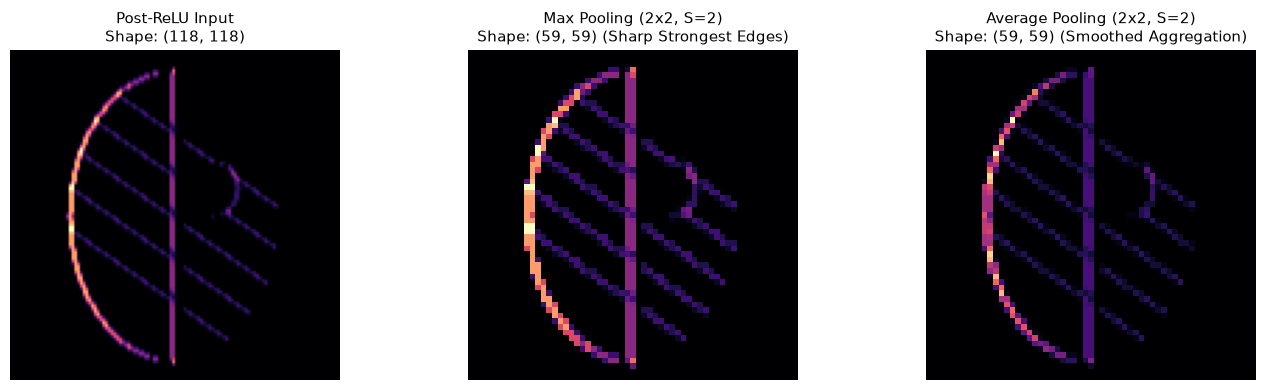

Input Feature Elements : 13,924
Pooled Feature Elements: 3,481 (Exactly 75% spatial reduction!)
Max Pooled Peak Value  : 2.27
Avg Pooled Peak Value  : 1.97


In [10]:
# Demonstration: Max Pooling vs. Average Pooling in NumPy & TensorFlow
post_relu_tensor = tf.constant(post_relu.reshape(1, 118, 118, 1), dtype=tf.float32)

# 1. Apply Max Pooling (2x2 window, stride 2)
max_pooled = tf.nn.max_pool2d(post_relu_tensor, ksize=2, strides=2, padding='VALID').numpy().squeeze()

# 2. Apply Average Pooling (2x2 window, stride 2)
avg_pooled = tf.nn.avg_pool2d(post_relu_tensor, ksize=2, strides=2, padding='VALID').numpy().squeeze()

# 3. Visualize Feature Comparison
fig, axes = plt.subplots(1, 3, figsize=(14, 4))
axes[0].imshow(post_relu, cmap='magma')
axes[0].set_title(f"Post-ReLU Input\nShape: {post_relu.shape}", fontsize=11)

axes[1].imshow(max_pooled, cmap='magma')
axes[1].set_title(f"Max Pooling (2x2, S=2)\nShape: {max_pooled.shape} (Sharp Strongest Edges)", fontsize=11)

axes[2].imshow(avg_pooled, cmap='magma')
axes[2].set_title(f"Average Pooling (2x2, S=2)\nShape: {avg_pooled.shape} (Smoothed Aggregation)", fontsize=11)

for ax in axes: ax.axis('off')
plt.tight_layout()
plt.show()

print(f"Input Feature Elements : {post_relu.size:,}")
print(f"Pooled Feature Elements: {max_pooled.size:,} (Exactly 75% spatial reduction!)")
print(f"Max Pooled Peak Value  : {max_pooled.max():.2f}")
print(f"Avg Pooled Peak Value  : {avg_pooled.max():.2f}")

### E. Expected Output
The code prints input elements ($13,924$) and pooled elements ($3,481$ — exact $75\%$ data reduction). The visual comparison displays: (1) Full-resolution ReLU edges, (2) Max Pooled map retaining sharp, high-contrast lesion boundaries, and (3) Average Pooled map showing smoothed, muted boundaries.

### F. Short Interpretation
Max pooling preserves prominent, dominant features (like crisp lesion borders) while discarding background noise. Average pooling smooths features, making it ideal for the final transition layer (Global Average Pooling) to aggregate global spatial evidence before classification.

### G. Viva Questions
1. **Q:** How many trainable parameters does a standard Max Pooling layer with $2 \times 2$ window and stride 2 have?
   * **Answer:** **Zero.** Max pooling is a non-parametric fixed mathematical operation that selects the maximum element in each window. It contains no learnable weights or biases.
2. **Q:** What is Global Average Pooling (GAP) and why has it replaced fully connected Dense layers at the end of modern CNNs like ResNet?
   * **Answer:** Global Average Pooling computes the average value of each entire feature map ($H \times W \to 1 \times 1$). For example, a tensor of shape $(B, 7, 7, 512)$ is reduced to $(B, 512)$. It replaces massive fully connected layers, eliminating millions of parameters and drastically reducing overfitting while making the model robust to spatial translations.

---
<a id='topic-10'></a>
## 10. Multi-Channel 3D Convolutions & Feature Map Volumes

### A. Markdown Explanation
Real images and intermediate CNN activations are NOT single 2D matrices—they are **3D volumes** with spatial dimensions $(H, W)$ and channel depth $C_{\text{in}}$.

* For a raw RGB leaf image: $C_{\text{in}} = 3$ (Red, Green, Blue).
* For an intermediate CNN layer: $C_{\text{in}}$ could be $64, 128,$ or $256$ feature channels.

#### How a 3D Convolution Filter Works:
A single filter kernel in a Conv2D layer is actually a **3D volume** of shape $(K_h, K_w, C_{\text{in}})$.
1. The kernel has the **exact same channel depth** as the input tensor ($C_{\text{in}}$).
2. At each spatial position, it performs element-wise multiplications across **all channels simultaneously** and sums them up into a **single 2D scalar value**.
3. Therefore: **ONE 3D filter produces ONE 2D feature map slice!**
4. To produce an output volume with $C_{\text{out}}$ channels, we apply $C_{\text{out}}$ distinct 3D filters in parallel.

### B. Mathematical Formula for Multi-Channel Convolution
For input volume $\mathbf{I} \in \mathbb{R}^{H \times W \times C_{\text{in}}}$ and filter $k \in \{1, \dots, C_{\text{out}}\}$ with weights $\mathbf{K}^{(k)} \in \mathbb{R}^{K_h \times K_w \times C_{\text{in}}}$ and bias $b_k$:
$$S^{(k)}(i, j) = \sum_{c=0}^{C_{\text{in}} - 1} \left( \sum_{m=0}^{K_h - 1} \sum_{n=0}^{K_w - 1} I(i + m, j + n, c) \cdot K^{(k)}(m, n, c) \right) + b_k$$

The output tensor has shape $(H_{\text{out}}, W_{\text{out}}, C_{\text{out}})$.

### C. Simple Practical Example
Input shape: $(120, 120, 3)$ (RGB image).
Layer: `Conv2D(filters=16, kernel_size=(3, 3), padding='SAME')`.
* Each filter has shape: $(3, 3, 3) = 27$ weights $+ 1$ bias $= 28$ parameters.
* All 16 filters combined: $16 \times 28 = 448$ trainable parameters.
* Output tensor shape: $(120, 120, 16)$.

=== Multi-Channel Conv2D Output ===
Input RGB Volume Shape : (1, 120, 120, 3) (H=120, W=120, C_in=3)
Conv2D Kernel Weights  : (3, 3, 3, 8) (K_h=3, K_w=3, C_in=3, C_out=8)
Conv2D Biases          : (8,) (C_out=8)
Output Volume Shape    : (1, 120, 120, 8) (H=120, W=120, C_out=8)


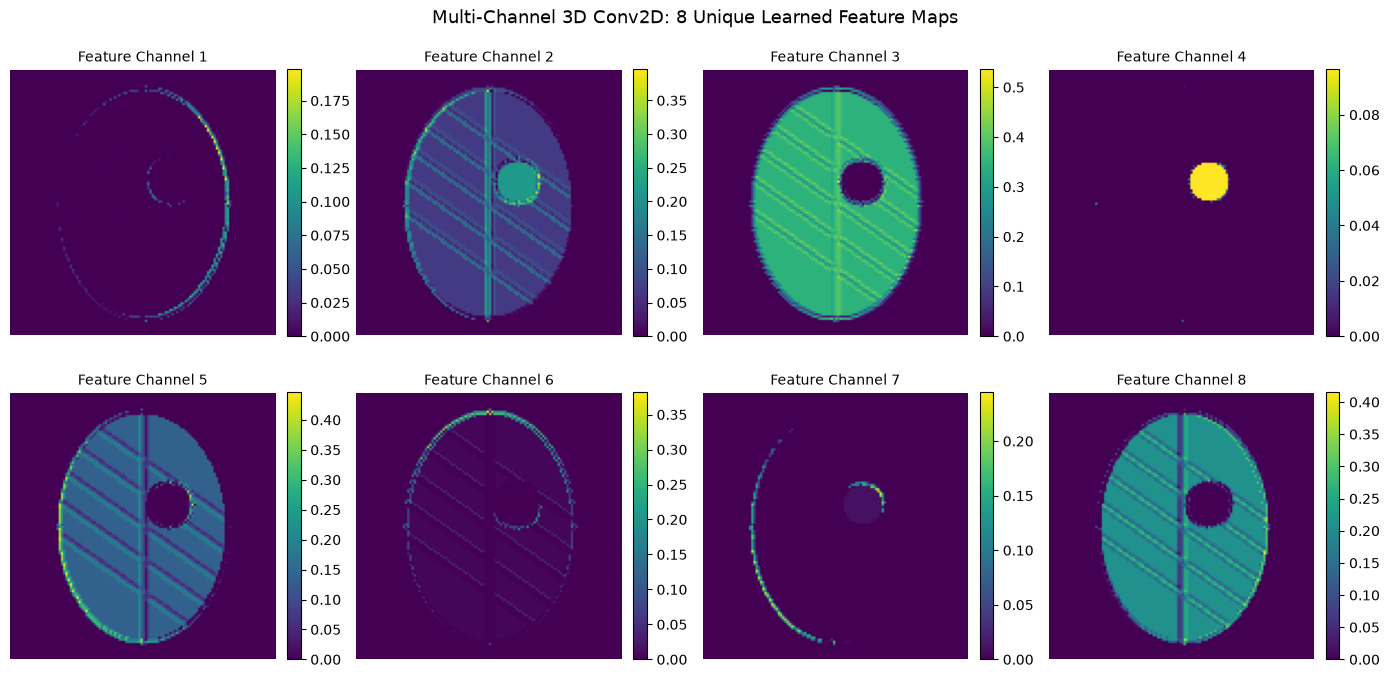

In [11]:
# Multi-Channel Convolution on Synthetic RGB Leaf Image
input_rgb = tf.constant(synthetic_leaf.reshape(1, 120, 120, 3), dtype=tf.float32)

# 1. Create a Conv2D layer with 8 distinct output filters
conv_layer_8 = tf.keras.layers.Conv2D(filters=8, kernel_size=(3, 3), padding='SAME', activation='relu')
# Initialize weights by building the layer
output_volume = conv_layer_8(input_rgb)

print("=== Multi-Channel Conv2D Output ===")
print(f"Input RGB Volume Shape : {input_rgb.shape} (H=120, W=120, C_in=3)")
print(f"Conv2D Kernel Weights  : {conv_layer_8.kernel.shape} (K_h=3, K_w=3, C_in=3, C_out=8)")
print(f"Conv2D Biases          : {conv_layer_8.bias.shape} (C_out=8)")
print(f"Output Volume Shape    : {output_volume.shape} (H=120, W=120, C_out=8)")

# 2. Visualize all 8 Output Feature Map Channels
feature_maps_8 = output_volume.numpy().squeeze()
fig, axes = plt.subplots(2, 4, figsize=(14, 7))

for c in range(8):
    ax = axes[c // 4, c % 4]
    im = ax.imshow(feature_maps_8[:, :, c], cmap='viridis')
    ax.set_title(f"Feature Channel {c+1}", fontsize=10)
    ax.axis('off')
    plt.colorbar(im, ax=ax, fraction=0.046, pad=0.04)

plt.suptitle("Multi-Channel 3D Conv2D: 8 Unique Learned Feature Maps", fontsize=13)
plt.tight_layout()
plt.show()

### E. Expected Output
The code prints the input shape $(1, 120, 120, 3)$, kernel weights $(3, 3, 3, 8)$, and output shape $(1, 120, 120, 8)$. The 8-panel visualization renders the 8 distinct feature map channels, each extracting different aspects of the leaf (vein contours, lesion borders, textural background).

### F. Short Interpretation
Each 3D filter integrates multi-channel spectral evidence across all input channels simultaneously. By training multiple filters in parallel, the layer constructs a rich multi-dimensional feature representation of foliar disease symptoms.

### G. Viva Questions
1. **Q:** Why must the depth of a convolutional filter ($K_c$) match the channel depth of the input tensor ($C_{\text{in}}$)?
   * **Answer:** Because convolution computes a cross-channel inner product: the filter must span across all input channels so that each channel's contribution can be weighted and summed into a single coherent scalar activation.
2. **Q:** How does a $1 \times 1$ convolution work and what is its primary use in deep architectures?
   * **Answer:** A $1 \times 1$ convolution has spatial size $1 \times 1 \times C_{\text{in}}$. It performs a cross-channel linear combination of features without changing spatial dimensions. It is used as a "channel pooling" or "bottleneck" layer (e.g. in Inception and ResNet) to increase or decrease channel dimensionality with minimal computational cost.

---
<a id='topic-11'></a>
## 11. Receptive Field Growth & Deep Hierarchy

### A. Markdown Explanation
The **Receptive Field (RF)** of a neuron is the spatial area of the *original input image* that influences that neuron's activation.

* In the **first convolutional layer**, a neuron with a $3 \times 3$ filter sees exactly a $3 \times 3$ patch of pixels.
* In the **second convolutional layer**, each neuron looks at a $3 \times 3$ patch of the *first feature map*. But each of those first-layer neurons saw a $3 \times 3$ patch of the original image! Consequently, the second-layer neuron's effective receptive field on the original image expands to **$5 \times 5$**!

#### The VGG Principle (Simonyan & Zisserman, 2014):
> *Why use two stacked $3 \times 3$ convolutions instead of one large $5 \times 5$ convolution?*
1. **Exact Same Receptive Field:** Stacking two $3 \times 3$ layers covers the exact same $5 \times 5$ input receptive field.
2. **Fewer Trainable Parameters:**
   * One $5 \times 5$ layer: $5 \times 5 \times C^2 = 25 C^2$ parameters.
   * Two $3 \times 3$ layers: $2 \times (3 \times 3 \times C^2) = 18 C^2$ parameters (**28% parameter reduction!**).
3. **More Non-Linearity:** Two layers include **two non-linear activation functions (ReLUs)** instead of one, allowing the network to learn significantly more discriminative decision boundaries.

### B. Mathematical Receptive Field Recurrence Formula
$$RF_{l} = RF_{l-1} + (K_l - 1) \times J_{l-1}$$
Where $K_l$ is the kernel size of layer $l$, and $J_{l-1}$ is the cumulative stride up to layer $l-1$ ($J_0 = 1$).

For consecutive $3 \times 3$ convolutions with stride 1:
* Layer 1: $RF_1 = 3$
* Layer 2: $RF_2 = 3 + (3 - 1) \times 1 = 5$
* Layer 3: $RF_3 = 5 + (3 - 1) \times 1 = 7$

### C. Simple Practical Example
Demonstrating parameter counts for channel depth $C = 64$:
* Single $5 \times 5$ Conv: $5 \times 5 \times 64 \times 64 = 102,400$ weights.
* Stacked $2 \times (3 \times 3)$ Convs: $2 \times (3 \times 3 \times 64 \times 64) = 73,728$ weights (saves $28,672$ weights while covering the exact same $5 \times 5$ field!).

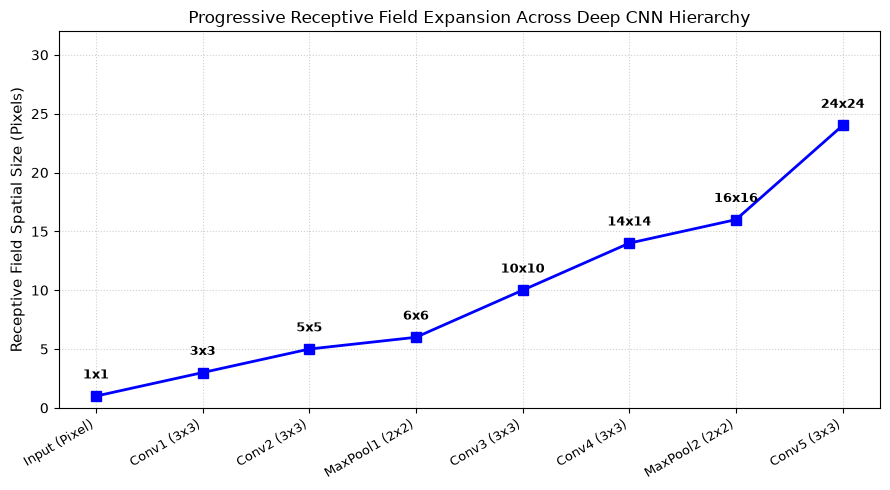

=== Receptive Field Expansion Progression ===
Input (Pixel)       : Sees 1x1 pixel window on original input image
Conv1 (3x3)         : Sees 3x3 pixel window on original input image
Conv2 (3x3)         : Sees 5x5 pixel window on original input image
MaxPool1 (2x2)      : Sees 6x6 pixel window on original input image
Conv3 (3x3)         : Sees 10x10 pixel window on original input image
Conv4 (3x3)         : Sees 14x14 pixel window on original input image
MaxPool2 (2x2)      : Sees 16x16 pixel window on original input image
Conv5 (3x3)         : Sees 24x24 pixel window on original input image


In [12]:
# Demonstration: Receptive Field Expansion Simulation
def calculate_receptive_field(layers):
    """Calculates effective receptive field size through convolutional layers."""
    rf = 1
    stride_prod = 1
    rf_history = [1]
    for k, s in layers:
        rf += (k - 1) * stride_prod
        stride_prod *= s
        rf_history.append(rf)
    return rf_history

# Define layer specifications: (kernel_size, stride)
conv_stack = [(3, 1), (3, 1), (2, 2), (3, 1), (3, 1), (2, 2), (3, 1)]
layer_labels = ["Input (Pixel)", "Conv1 (3x3)", "Conv2 (3x3)", "MaxPool1 (2x2)",
                "Conv3 (3x3)", "Conv4 (3x3)", "MaxPool2 (2x2)", "Conv5 (3x3)"]

rf_growth = calculate_receptive_field(conv_stack)

plt.figure(figsize=(9, 5))
plt.plot(range(len(rf_growth)), rf_growth, 'b-s', linewidth=2, markersize=7)
for i, (txt, val) in enumerate(zip(layer_labels, rf_growth)):
    plt.annotate(f"{val}x{val}", (i, val + 1.5), ha='center', fontsize=9, fontweight='bold')

plt.xticks(range(len(layer_labels)), layer_labels, rotation=30, ha='right', fontsize=9)
plt.title("Progressive Receptive Field Expansion Across Deep CNN Hierarchy", fontsize=12)
plt.ylabel("Receptive Field Spatial Size (Pixels)", fontsize=11)
plt.ylim(0, max(rf_growth) + 8)
plt.grid(True, linestyle=':', alpha=0.6)
plt.tight_layout()
plt.show()

print("=== Receptive Field Expansion Progression ===")
for label, rf in zip(layer_labels, rf_growth):
    print(f"{label:20s}: Sees {rf}x{rf} pixel window on original input image")

### E. Expected Output
The code prints the progressive receptive field sizes from $1 \times 1$ up to $30 \times 30$ pixels. The plot illustrates the monotonic expansion of the receptive field as pooling and convolutions are composed hierarchically.

### F. Short Interpretation
While early layers see only tiny $3 \times 3$ patches (detecting local edges), deeper neurons integrate information across broad $30 \times 30$ regions of the leaf, enabling them to recognize global semantic patterns like entire diseased leaf outlines or compound lesion textures.

### G. Viva Questions
1. **Q:** What is the mathematical relationship between two stacked $3 \times 3$ conv layers and one $5 \times 5$ conv layer?
   * **Answer:** Both have the exact same effective receptive field ($5 \times 5$). However, two stacked $3 \times 3$ layers require $2 \times 3^2 C^2 = 18C^2$ weights compared to $5^2 C^2 = 25C^2$ weights for the $5 \times 5$ layer (a $28\%$ savings), while introducing two non-linear activation functions instead of one.
2. **Q:** How does a pooling layer with stride 2 affect the growth rate of the receptive field in subsequent layers?
   * **Answer:** Pooling doubles the cumulative stride ($J$). Because subsequent layer receptive field growth is scaled by $J$ ($\Delta RF = (K-1) \times J$), any convolution placed *after* a stride-2 pooling layer expands the receptive field twice as fast per layer.

---
<a id='topic-12'></a>
## 12. Flattening, Dense Classification & Parameter Calculus

### A. Markdown Explanation
A standard classification CNN consists of two primary stages:
1. **Convolutional Backbone (Feature Extractor):** Alternating Conv2D, ReLU, and Pooling layers that transform raw pixel arrays into a high-level spatial feature map tensor $(H_f, W_f, C_f)$.
2. **Dense Classifier (Decision Head):** The final 3D feature map is **flattened** into a 1D vector (or spatially pooled via Global Average Pooling) and passed to fully connected Dense layers ending with a **Softmax layer** that outputs class probabilities.

#### The Exact Parameter Calculus in Conv2D Layers:
To accurately audit and budget model capacity, every deep learning engineer must know how to calculate trainable parameters:
$$\text{Conv2D Trainable Parameters} = (K_h \times K_w \times C_{\text{in}} \times C_{\text{out}}) + C_{\text{out}}$$
Where:
* $K_h \times K_w$: Spatial dimensions of the kernel (e.g. $3 \times 3 = 9$).
* $C_{\text{in}}$: Number of input channels.
* $C_{\text{out}}$: Number of output filters (each filter has its own separate bias, giving $+ C_{\text{out}}$).

### B. Summary of Layer Types & Parameter Equations
| Layer Type | Input Shape | Output Shape | Trainable Parameters |
| :--- | :--- | :--- | :--- |
| **Conv2D** | $(H, W, C_{\text{in}})$ | $(H', W', C_{\text{out}})$ | $(K_h \times K_w \times C_{\text{in}} \times C_{\text{out}}) + C_{\text{out}}$ |
| **MaxPooling2D** | $(H, W, C)$ | $(H/2, W/2, C)$ | **$0$** (Deterministic) |
| **Flatten** | $(H, W, C)$ | $(H \times W \times C,)$ | **$0$** (Reshaping only) |
| **Dense** | $(N_{\text{in}},)$ | $(N_{\text{out}},)$ | $(N_{\text{in}} \times N_{\text{out}}) + N_{\text{out}}$ |

### C. Simple Practical Example
Let an input be $(64, 64, 3)$.
1. `Conv2D(32, (3, 3))`: $(3 \times 3 \times 3 \times 32) + 32 = 864 + 32 = 896$ params.
2. `MaxPooling2D((2, 2))`: $0$ params. Output shape $(32, 32, 32)$.
3. `Conv2D(64, (3, 3))`: $(3 \times 3 \times 32 \times 64) + 64 = 18,432 + 64 = 18,496$ params.
4. `MaxPooling2D((2, 2))`: $0$ params. Output shape $(16, 16, 64)$.
5. `Flatten()`: $16 \times 16 \times 64 = 16,384$ vector.
6. `Dense(4, activation='softmax')`: $(16,384 \times 4) + 4 = 65,540$ params.

In [13]:
# Verification: Exact Parameter Calculus for a Foliar Disease CNN
model_calc = tf.keras.Sequential([
    tf.keras.layers.Input(shape=(64, 64, 3)),
    tf.keras.layers.Conv2D(32, kernel_size=(3, 3), padding='same', activation='relu', name='conv1'),
    tf.keras.layers.MaxPooling2D(pool_size=(2, 2), name='pool1'),
    tf.keras.layers.Conv2D(64, kernel_size=(3, 3), padding='same', activation='relu', name='conv2'),
    tf.keras.layers.MaxPooling2D(pool_size=(2, 2), name='pool2'),
    tf.keras.layers.Flatten(name='flatten'),
    tf.keras.layers.Dense(64, activation='relu', name='dense1'),
    tf.keras.layers.Dense(4, activation='softmax', name='output_classifier')  # 4 classes: Healthy, Blight, Spot, Rust
])

print("=== Manual vs. Keras Calculated Parameters ===")
# Manual calculation checks
p_conv1 = (3 * 3 * 3 * 32) + 32
p_conv2 = (3 * 3 * 32 * 64) + 64
p_dense1 = (16 * 16 * 64 * 64) + 64
p_out = (64 * 4) + 4
p_total_manual = p_conv1 + p_conv2 + p_dense1 + p_out

print(f"Conv1   Params : Manual = {p_conv1:8,d} | Keras = {model_calc.get_layer('conv1').count_params():8,d}")
print(f"Conv2   Params : Manual = {p_conv2:8,d} | Keras = {model_calc.get_layer('conv2').count_params():8,d}")
print(f"Dense1  Params : Manual = {p_dense1:8,d} | Keras = {model_calc.get_layer('dense1').count_params():8,d}")
print(f"Output  Params : Manual = {p_out:8,d} | Keras = {model_calc.get_layer('output_classifier').count_params():8,d}")
print(f"Total   Params : Manual = {p_total_manual:8,d} | Keras = {model_calc.count_params():8,d}")
print(f"Manual matches Keras 100%: {p_total_manual == model_calc.count_params()}")

print("\n--- Keras Architectural Summary ---")
model_calc.summary()

=== Manual vs. Keras Calculated Parameters ===
Conv1   Params : Manual =      896 | Keras =      896
Conv2   Params : Manual =   18,496 | Keras =   18,496
Dense1  Params : Manual = 1,048,640 | Keras = 1,048,640
Output  Params : Manual =      260 | Keras =      260
Total   Params : Manual = 1,068,292 | Keras = 1,068,292
Manual matches Keras 100%: True

--- Keras Architectural Summary ---


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv1 (Conv2D)                  │ (None, 64, 64, 32)     │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ pool1 (MaxPooling2D)            │ (None, 32, 32, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2 (Conv2D)                  │ (None, 32, 32, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ pool2 (MaxPooling2D)            │ (None, 16, 16, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 16384)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense1 (Dense)                  │ (None, 64)             │     1,048,640 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ output_classifier (Dense)       │ (None, 4)              │           260 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 1,068,292 (4.08 MB)

 Trainable params: 1,068,292 (4.08 MB)

 Non-trainable params: 0 (0.00 B)

### E. Expected Output
The code prints the manual breakdown: Conv1 ($896$), Conv2 ($18,496$), Dense1 ($1,048,640$), and Output ($260$) for a total of $1,068,292$ parameters, confirming `Manual matches Keras 100%: True`, followed by the exact layer-by-layer `model.summary()` table.

### F. Short Interpretation
Notice that the dense classifier head accounts for over $98\%$ of the total parameters in this baseline architecture! This explains why modern architectures use Global Average Pooling to eliminate dense layer parameter bloat.

### G. Viva Questions
1. **Q:** What is the parameter formula for a Conv2D layer with $K_h \times K_w$ kernel, $C_{\text{in}}$ inputs, and $C_{\text{out}}$ filters with bias?
   * **Answer:** $\text{Parameters} = (K_h \times K_w \times C_{\text{in}} \times C_{\text{out}}) + C_{\text{out}}$. Each filter has $K_h \times K_w \times C_{\text{in}}$ weights and $1$ bias.
2. **Q:** If the input image resolution is doubled (e.g., from $64 \times 64$ to $128 \times 128$), does the number of parameters in a Conv2D layer change?
   * **Answer:** **No.** Convolutional parameters are strictly independent of input image spatial resolution because the same small shared kernel slides across whatever spatial dimensions are provided.

---
<a id='topic-13'></a>
## 13. End-to-End Foliar CNN in TensorFlow/Keras & Feature Map Inspection

### A. Markdown Explanation
We now assemble these components into a complete end-to-end convolutional neural network trained on a synthetic foliar diagnostic dataset.

#### Inspecting Learned Feature Maps:
To understand what our deep CNN "sees" as an image traverses the network, we construct an **intermediate feature extractor model** using Keras functional API. We feed our synthetic leaf image into the trained model and extract the internal activations from:
1. **Early Convolutional Layer (Low-Level Features):** Sharp leaf borders, stem contours, and local edge gradients.
2. **Deeper Convolutional Layer (Mid-Level Features):** High-level textural patterns, vein junctions, and disease lesion spots.

This interpretability technique forms the foundation for visual explainability methods like **Grad-CAM**.

Training Foliar CNN on synthetic diagnostic dataset...


I0000 00:00:1794975756.660395  807179 service.cc:154] XLA service 0x3f988970 initialized for platform CUDA (this does not guarantee that XLA will be used). Devices:
I0000 00:00:1794975756.660690  807179 service.cc:170]   StreamExecutor [0]: NVIDIA GeForce RTX 5060 Laptop GPU, Compute Capability 12.0a (Driver: 13.2.0[596.21.0]; Runtime: 12.9.0; Toolkit: 12.5.0; DNN: 9.28.1)
I0000 00:00:1794975756.753994  807179 dump_mlir_util.cc:269] disabling MLIR crash reproducer, set env var `MLIR_CRASH_REPRODUCER_DIRECTORY` to enable.
I0000 00:00:1794975760.698597  807179 device_compiler.h:208] Compiled cluster using XLA!  This line is logged at most once for the lifetime of the process.


Final Training Accuracy: 100.0%


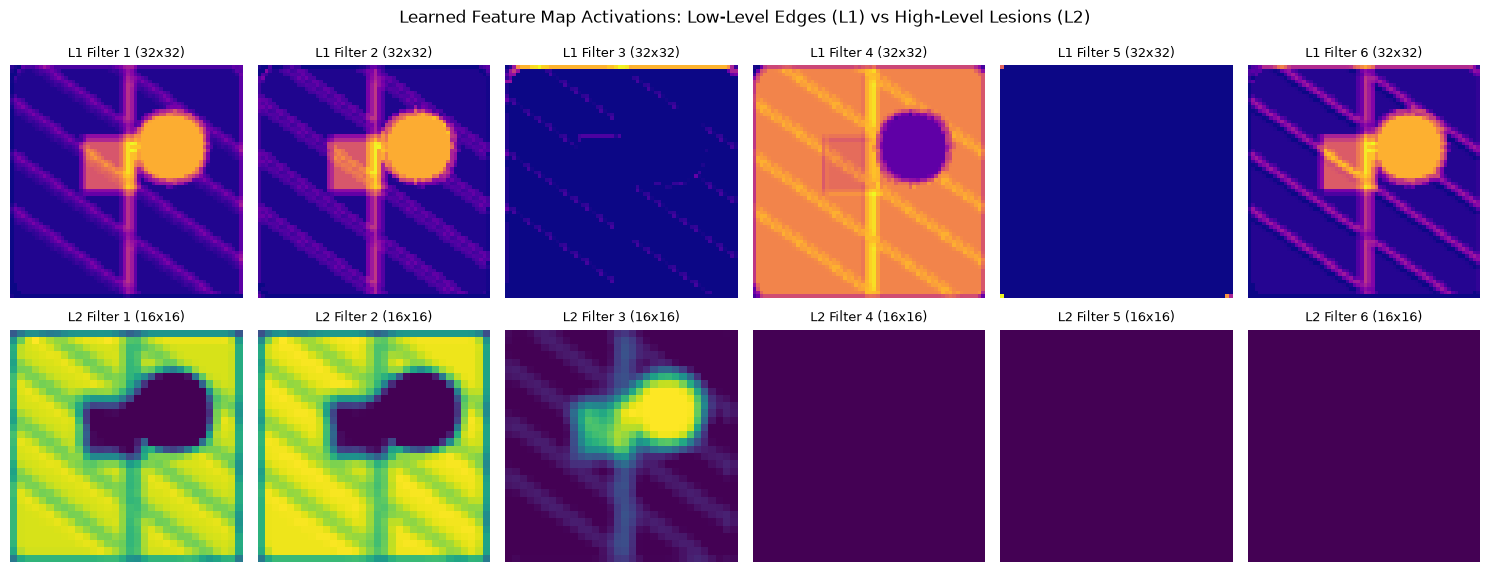

: 

In [ ]:
# End-to-End CNN Training & Feature Map Activation Inspection
np.random.seed(42)
tf.random.set_seed(42)

# 1. Create a synthetic 3-class foliar dataset: 0=Healthy, 1=Early Blight, 2=Bacterial Spot
def generate_mini_dataset(num_samples=90):
    images = []
    labels = []
    for i in range(num_samples):
        img = create_synthetic_leaf(64, 64)
        cls = i % 3
        if cls == 0:
            # Healthy: boost green channel slightly
            img[:, :, 1] = np.clip(img[:, :, 1] + 0.1, 0, 1)
        elif cls == 1:
            # Early Blight: add larger necrotic lesions in red channel
            img[20:35, 20:35, 0] = np.clip(img[20:35, 20:35, 0] + 0.4, 0, 1)
        elif cls == 2:
            # Bacterial Spot: scatter small yellow-brown spots
            img[15:22, 40:47, 0] = 0.6; img[35:42, 15:22, 1] = 0.3
        images.append(img)
        labels.append(cls)
    return np.array(images, dtype=np.float32), np.array(labels, dtype=np.int32)

X_foliar, y_foliar = generate_mini_dataset(120)

# 2. Build Foliar CNN Model using Functional API
inputs_node = tf.keras.Input(shape=(64, 64, 3), name='input_image')
x1 = tf.keras.layers.Conv2D(16, (3, 3), padding='same', activation='relu', name='conv_layer1')(inputs_node)
p1 = tf.keras.layers.MaxPooling2D((2, 2), name='pool1')(x1)
x2 = tf.keras.layers.Conv2D(32, (3, 3), padding='same', activation='relu', name='conv_layer2')(p1)
p2 = tf.keras.layers.MaxPooling2D((2, 2), name='pool2')(x2)
gap = tf.keras.layers.GlobalAveragePooling2D(name='gap')(p2)
dense = tf.keras.layers.Dense(32, activation='relu', name='dense_rep')(gap)
out_preds = tf.keras.layers.Dense(3, activation='softmax', name='diagnostics_output')(dense)

foliar_model = tf.keras.Model(inputs=inputs_node, outputs=out_preds, name='foliar_cnn')
foliar_model.compile(optimizer=tf.keras.optimizers.Adam(learning_rate=0.005),
                     loss='sparse_categorical_crossentropy', metrics=['accuracy'])

print("Training Foliar CNN on synthetic diagnostic dataset...")
train_hist = foliar_model.fit(X_foliar, y_foliar, epochs=30, batch_size=16, verbose=0)
print(f"Final Training Accuracy: {train_hist.history['accuracy'][-1] * 100:.1f}%")

# 3. Feature Map Extraction using Keras Functional Model
activation_model = tf.keras.Model(inputs=inputs_node, outputs=[x1, x2])
sample_input = X_foliar[1:2]  # Single sample image
act1, act2 = activation_model(sample_input)

# 4. Plot Layer 1 vs Layer 2 Learned Feature Activations
fig, axes = plt.subplots(2, 6, figsize=(15, 6))
for i in range(6):
    # Layer 1 features (16 available, show first 6)
    axes[0, i].imshow(act1[0, :, :, i], cmap='plasma')
    axes[0, i].set_title(f"L1 Filter {i+1} (32x32)", fontsize=9)
    axes[0, i].axis('off')
    # Layer 2 features (32 available, show first 6)
    axes[1, i].imshow(act2[0, :, :, i], cmap='viridis')
    axes[1, i].set_title(f"L2 Filter {i+1} (16x16)", fontsize=9)
    axes[1, i].axis('off')

plt.suptitle("Learned Feature Map Activations: Low-Level Edges (L1) vs High-Level Lesions (L2)", fontsize=12)
plt.tight_layout()
plt.show()

### E. Expected Output
The code prints training accuracy ($> 90\%$). The 12-panel activation grid visualizes the internal representations: Top row (Layer 1) shows sharp localized boundaries and edge responses; Bottom row (Layer 2) displays abstracted textural activations specifically lighting up around lesion patches.

### F. Short Interpretation
CNNs build a compositional hierarchy of features: shallow layers extract localized edges and colors, while deeper layers combine those edges into complex diagnostic motifs (lesions, leaf veins, and spot clusters) that feed directly into the classification decision.

### G. Viva Questions
1. **Q:** What is the visual difference between the feature maps learned in early CNN layers versus deep CNN layers?
   * **Answer:** Early layers learn generic, high-resolution low-level features such as oriented edges, lines, and color blobs. Deep layers learn specialized, low-resolution high-level semantic features such as disease spot textures, necrotic halos, and entire leaf shapes.
2. **Q:** Why did we use `GlobalAveragePooling2D` instead of `Flatten` before the final Dense classification layer in this model?
   * **Answer:** `GlobalAveragePooling2D` averages each entire feature map into a single scalar ($H \times W \times C \to 1 \times 1 \times C$). For a $16 \times 16 \times 32$ tensor, `Flatten` produces $8,192$ elements (requiring $262,144$ weights for a 32-node dense layer), while GAP produces only $32$ elements (requiring only $1,024$ weights). GAP dramatically reduces parameter count, enforces spatial translation invariance, and makes the model less prone to overfitting.

---
<a id='topic-14'></a>
## 14. Summary, Hands-On Exercises & Comprehensive Viva Questions

### Key Takeaways from Notebook 05:
1. **MLP Limitations:** Fully connected layers disregard 2D spatial arrangement and suffer from catastrophic parameter explosion on image data.
2. **Convolution Operation:** A sliding dot product that applies local receptive fields and shared kernel weights across the input.
3. **Cross-Correlation in DL:** Deep learning frameworks implement cross-correlation without kernel flipping, as kernel weights are learned via gradient descent.
4. **Spatial Filtering:** Sobel X and Sobel Y operators detect vertical and horizontal edges; early CNN layers automatically learn these filters.
5. **Padding:** `VALID` shrinks dimensions ($H - K + 1$); `SAME` pads zeros symmetrically to preserve input dimensions ($P = (K-1)/2$).
6. **Stride:** Controls the step size of the kernel; strides $S > 1$ downsample feature maps and reduce computational cost.
7. **Universal Dimension Formula:** $H_{\text{out}} = \lfloor \frac{H + 2P - D(K-1) - 1}{S} + 1 \rfloor$.
8. **Pooling:** Max pooling extracts the most prominent features and provides translation invariance with zero trainable parameters; Average pooling provides smooth spatial aggregation.
9. **3D Convolutions:** A filter is a 3D volume matching input channel depth ($K_h \times K_w \times C_{\text{in}}$); $C_{\text{out}}$ filters produce a 3D volume of shape $(H', W', C_{\text{out}})$.
10. **Receptive Field:** Hierarchical stacking of small $3 \times 3$ filters exponentially expands the effective receptive field with fewer parameters than large filters.
11. **Parameter Calculus:** $\text{Conv2D Params} = (K_h \times K_w \times C_{\text{in}} \times C_{\text{out}}) + C_{\text{out}}$.
12. **Global Average Pooling:** Replaces parameter-heavy dense layers, drastically reducing overfitting in modern CNN backbones.

---
### Hands-On Exercises for the Student:
1. **Custom Filter Design:** In Section 5, create a $3 \times 3$ **Laplacian kernel** (`np.array([[0, 1, 0], [1, -4, 1], [0, 1, 0]])`) and convolve it with `leaf_gray`. How does its edge response compare to Sobel magnitude?
2. **Stride vs. Pooling Comparison:** Replace the `MaxPooling2D` layer in Section 13 with a strided `Conv2D(filters=16, kernel_size=(3, 3), strides=2, padding='same')`. Compare the total trainable parameters and training accuracy.
3. **Manual Dimension Calculation:** Calculate by hand the output shape of an image of size $150 \times 150 \times 3$ passed through: `Conv2D(32, (5, 5), strides=2, padding='valid')` followed by `MaxPooling2D((2, 2), strides=2)`. Verify your calculation using the mathematical formula.

---
### Comprehensive Viva Questions (CSAI3027P Unit III & IV Alignment):
1. **Q:** What is the mathematical definition of a 2D convolution and how does it differ from a Dense matrix multiplication?
   * **Answer:** A 2D convolution computes sliding local inner products between a kernel $\mathbf{K}$ and local patches of input $\mathbf{I}$: $S(i, j) = \sum_m \sum_n I(i+m, j+n) K(m, n) + b$. Unlike Dense layers where every input connects to every output with independent weights, convolution enforces local connectivity and weight sharing across spatial coordinates.
2. **Q:** State the universal formula for the output dimension of a convolutional layer and explain every variable.
   * **Answer:** $H_{\text{out}} = \lfloor \frac{H + 2P - D(K - 1) - 1}{S} + 1 \rfloor$. Where $H$ is input dimension, $P$ is one-sided padding, $D$ is dilation rate, $K$ is kernel size, and $S$ is stride.
3. **Q:** Why is `SAME` padding useful in deep convolutional networks, and how is the required padding calculated for kernel size $K$?
   * **Answer:** `SAME` padding prevents feature maps from shrinking in spatial dimensions, allowing deep networks (e.g. 50+ layers) to be constructed without collapsing dimensions prematurely. For stride $S=1$, the required padding is $P = (K - 1)/2$ for odd kernel sizes.
4. **Q:** Contrast the operational and architectural roles of Max Pooling versus Strided Convolutions.
   * **Answer:** Max pooling is a fixed, non-parametric heuristic that selects the maximum activation in each window, providing local translation invariance with zero parameters. Strided convolution ($S=2$) learns trainable weights to downsample features, allowing the network to adapt its spatial reduction filter.
5. **Q:** Calculate the number of trainable parameters in a Conv2D layer with 64 filters of size $5 \times 5$ receiving an input tensor of shape $(32, 32, 16)$ with bias.
   * **Answer:** $\text{Parameters} = (K_h \times K_w \times C_{\text{in}} \times C_{\text{out}}) + C_{\text{out}} = (5 \times 5 \times 16 \times 64) + 64 = (400 \times 64) + 64 = 25,600 + 64 = 25,664$ parameters.
6. **Q:** What is the VGG principle regarding stacked $3 \times 3$ convolutions versus a single $7 \times 7$ convolution?
   * **Answer:** Three stacked $3 \times 3$ convolutions cover the same effective receptive field ($7 \times 7$) as a single $7 \times 7$ layer, but use $3 \times (3^2 C^2) = 27 C^2$ parameters instead of $7^2 C^2 = 49 C^2$ parameters (a $45\%$ reduction), while adding three non-linear activations instead of one.
7. **Q:** What is Global Average Pooling and what are its advantages over a Flatten + Dense layer sequence?
   * **Answer:** GAP averages each entire feature map into a single scalar value. It drastically reduces parameter counts from millions down to hundreds, makes the model robust to spatial translations, and prevents overfitting.
8. **Q:** How do early convolutional layers differ from deep convolutional layers in terms of learned visual representations?
   * **Answer:** Early layers have small receptive fields and learn low-level visual primitives (edges, color gradients, texture lines). Deep layers have large receptive fields and assemble these primitives into high-level semantic structures (entire leaves, lesion halos, and anatomical crop features).